In [7]:
print("Atiq Ur Rehman")
print("Assignment2")
print("75923")

Atiq Ur Rehman
Assignment2
75923


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

df = pd.read_csv("penguins.csv")
print("First 5 records:")
display(df.head())
print("Last 5 records:")
display(df.tail())

First 5 records:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Last 5 records:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,MALE


In [2]:
print("Rows, Columns:", df.shape)
print("\nColumn names:", list(df.columns))
print("\nData types:")
print(df.dtypes)

Rows, Columns: (344, 7)

Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']

Data types:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object


In [3]:
print("Numerical summary:")
display(df.describe())
print("Categorical summary:")
display(df.describe(include='object'))

Numerical summary:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


Categorical summary:


/tmp/ipykernel_161/4231200425.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object'))


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,MALE
freq,152,168,168


## Task 2

In [4]:
missing = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
report_before = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
print("BEFORE handling:")
display(report_before)
print("Total missing cells:", int(missing.sum()), "| Rows with at least one missing value:", int(df.isnull().any(axis=1).sum()))

BEFORE handling:


,Missing Count,Missing %
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20


Total missing cells: 19 | Rows with at least one missing value: 11


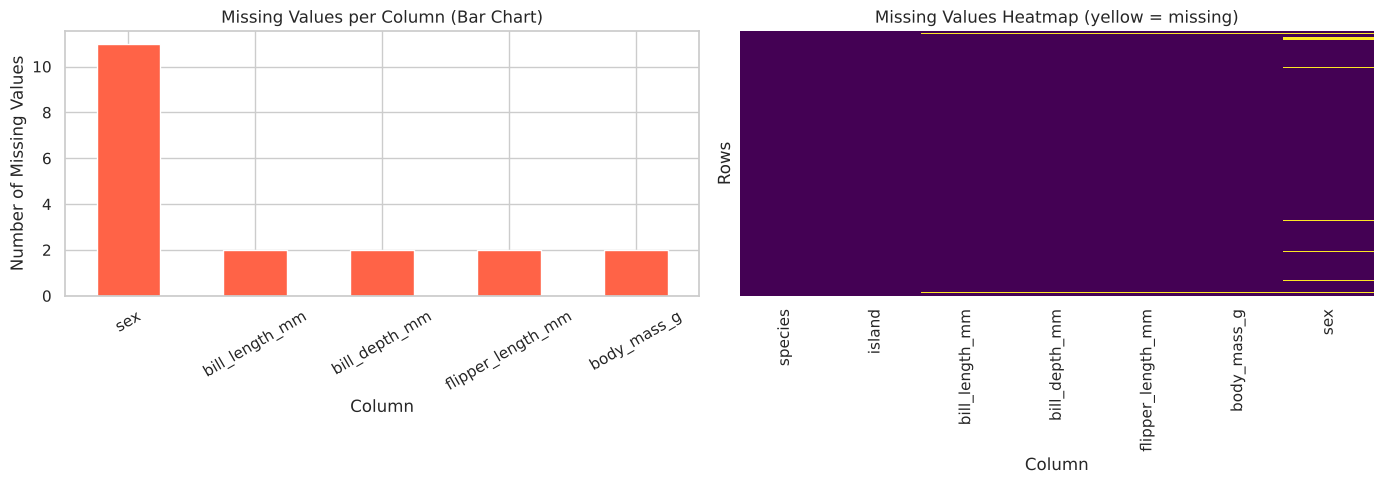

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
missing[missing > 0].sort_values(ascending=False).plot(kind="bar", ax=axes[0], color="tomato")
axes[0].set_title("Missing Values per Column (Bar Chart)")
axes[0].set_xlabel("Column")
axes[0].set_ylabel("Number of Missing Values")
axes[0].tick_params(axis="x", rotation=30)
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[1])
axes[1].set_title("Missing Values Heatmap (yellow = missing)")
axes[1].set_xlabel("Column")
axes[1].set_ylabel("Rows")
plt.tight_layout()
plt.savefig("figures/task2_missing_values.png", dpi=150)
plt.show()

In [6]:
# Work on a copy so the original stays available for the before/after comparison
df_clean = df.copy()
num_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
cat_cols = df_clean.select_dtypes(include="object").columns.tolist()

# Compare skewness to decide mean vs median
print("Skewness of numeric columns:")
print(df_clean[num_cols].skew().round(3))
print("\nMean vs Median:")
display(pd.DataFrame({"mean": df_clean[num_cols].mean(), "median": df_clean[num_cols].median()}).round(2))

Skewness of numeric columns:
bill_length_mm       0.053
bill_depth_mm       -0.143
flipper_length_mm    0.346
body_mass_g          0.470
dtype: float64

Mean vs Median:


/tmp/ipykernel_161/4012929067.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_clean.select_dtypes(include="object").columns.tolist()


,mean,median
bill_length_mm,43.92,44.45
bill_depth_mm,17.15,17.30
flipper_length_mm,200.92,197.00
body_mass_g,4201.75,4050.00


In [7]:
# Numerical -> median, Categorical -> mode
for c in num_cols:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())
for c in cat_cols:
    df_clean[c] = df_clean[c].fillna(df_clean[c].mode()[0])

report_after = pd.DataFrame({"Missing Count": df_clean.isnull().sum(),
                             "Missing %": (df_clean.isnull().mean() * 100).round(2)})
print("BEFORE vs AFTER:")
display(pd.concat([report_before.add_suffix(" (before)"), report_after.add_suffix(" (after)")], axis=1))
print("Mode used for sex:", df["sex"].mode()[0])

BEFORE vs AFTER:


,Missing Count (before),Missing % (before),Missing Count (after),Missing % (after)
species,0,0.00,0,0.0
island,0,0.00,0,0.0
bill_length_mm,2,0.58,0,0.0
bill_depth_mm,2,0.58,0,0.0
flipper_length_mm,2,0.58,0,0.0
body_mass_g,2,0.58,0,0.0
sex,11,3.20,0,0.0


Mode used for sex: MALE


## Task 3 

In [8]:
dups_before = df_clean.duplicated().sum()
print("Duplicate rows BEFORE:", dups_before)
display(df_clean[df_clean.duplicated(keep=False)])
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Duplicate rows AFTER:", df_clean.duplicated().sum())
print("Shape after:", df_clean.shape)

Duplicate rows BEFORE: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex


Duplicate rows AFTER: 0
Shape after: (344, 7)


## Task 4 

In [9]:
cat_cols = df_clean.select_dtypes(include="object").columns.tolist()
print("Categorical columns:", cat_cols)
print()
for c in cat_cols:
    print(f"--- {c} (BEFORE) ---")
    print(df_clean[c].value_counts(dropna=False).to_dict())
    print("Values with stray spaces:", int((df_clean[c] != df_clean[c].str.strip()).sum()))
    print("Distinct raw values:", sorted(df_clean[c].unique()))
    print()

Categorical columns: ['species', 'island', 'sex']

--- species (BEFORE) ---
{'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68}
Values with stray spaces: 0
Distinct raw values: ['Adelie', 'Chinstrap', 'Gentoo']

--- island (BEFORE) ---
{'Biscoe': 168, 'Dream': 124, 'Torgersen': 52}
Values with stray spaces: 0
Distinct raw values: ['Biscoe', 'Dream', 'Torgersen']

--- sex (BEFORE) ---
{'MALE': 179, 'FEMALE': 165}
Values with stray spaces: 0
Distinct raw values: ['FEMALE', 'MALE']



/tmp/ipykernel_161/328625893.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_clean.select_dtypes(include="object").columns.tolist()


In [10]:
before_sex = df_clean["sex"].copy()
for c in cat_cols:
    df_clean[c] = df_clean[c].str.strip().str.title()

comparison = pd.DataFrame({
    "sex BEFORE": before_sex.value_counts(),
    "sex AFTER": df_clean["sex"].value_counts()
})
display(comparison)
for c in cat_cols:
    print(c, "->", sorted(df_clean[c].unique()))

,sex BEFORE,sex AFTER
sex,,
FEMALE,165.0,NaN
Female,NaN,165.0
MALE,179.0,NaN
Male,NaN,179.0


species -> ['Adelie', 'Chinstrap', 'Gentoo']
island -> ['Biscoe', 'Dream', 'Torgersen']
sex -> ['Female', 'Male']


## Task 5 

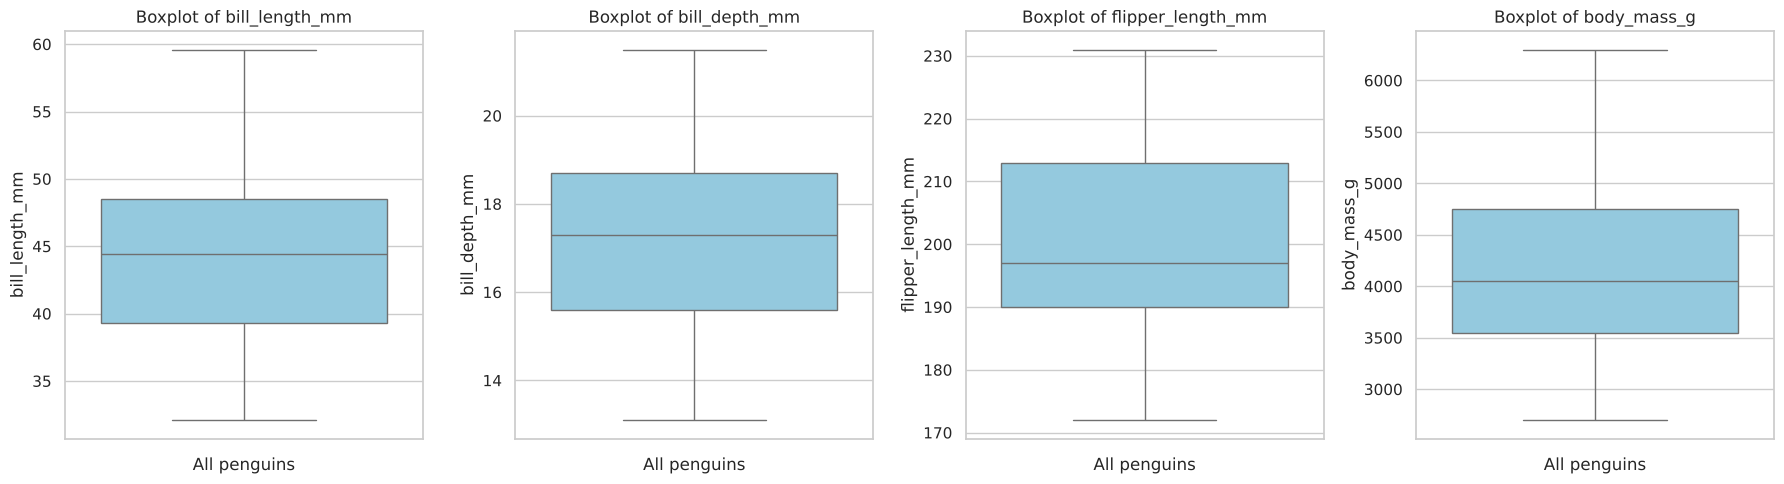

In [11]:
outlier_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, c in zip(axes, outlier_cols):
    sns.boxplot(y=df_clean[c], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot of {c}")
    ax.set_ylabel(c)
    ax.set_xlabel("All penguins")
plt.tight_layout()
plt.savefig("figures/task5_boxplots.png", dpi=150)
plt.show()

In [12]:
rows = []
for c in outlier_cols:
    Q1, Q3 = df_clean[c].quantile(0.25), df_clean[c].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df_clean[c] < lower) | (df_clean[c] > upper)).sum()
    rows.append([c, Q1, Q3, IQR, lower, upper, n_out, df_clean[c].min(), df_clean[c].max()])
iqr_table = pd.DataFrame(rows, columns=["Column", "Q1", "Q3", "IQR", "Lower bound", "Upper bound",
                                        "# Outliers", "Min", "Max"]).round(2)
display(iqr_table)

,Column,Q1,Q3,IQR,Lower bound,Upper bound,# Outliers,Min,Max
0,bill_length_mm,39.28,48.5,9.23,25.44,62.34,0,32.1,59.6
1,bill_depth_mm,15.60,18.7,3.10,10.95,23.35,0,13.1,21.5
2,flipper_length_mm,190.00,213.0,23.00,155.50,247.50,0,172.0,231.0
3,body_mass_g,3550.00,4750.0,1200.00,1750.00,6550.00,0,2700.0,6300.0


In [13]:
# Extra investigation: are the extremes plausible for their species? (check within species)
display(df_clean.groupby("species")[outlier_cols].agg(["min", "max"]).round(1))
print("Smallest and largest body mass records:")
display(df_clean.sort_values("body_mass_g").iloc[[0, 1, -2, -1]])

bill_length_mm       bill_depth_mm       flipper_length_mm         \
                     min   max           min   max               min    max   
species                                                                       
Adelie              32.1  46.0          15.5  21.5             172.0  210.0   
Chinstrap           40.9  58.0          16.4  20.8             178.0  212.0   
Gentoo              40.9  59.6          13.1  17.3             197.0  231.0   

          body_mass_g          
                  min     max  
species                        
Adelie         2850.0  4775.0  
Chinstrap      2700.0  4800.0  
Gentoo         3950.0  6300.0

Smallest and largest body mass records:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
190,Chinstrap,Dream,46.9,16.6,192.0,2700.0,Female
58,Adelie,Biscoe,36.5,16.6,181.0,2850.0,Female
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male


## Task 6

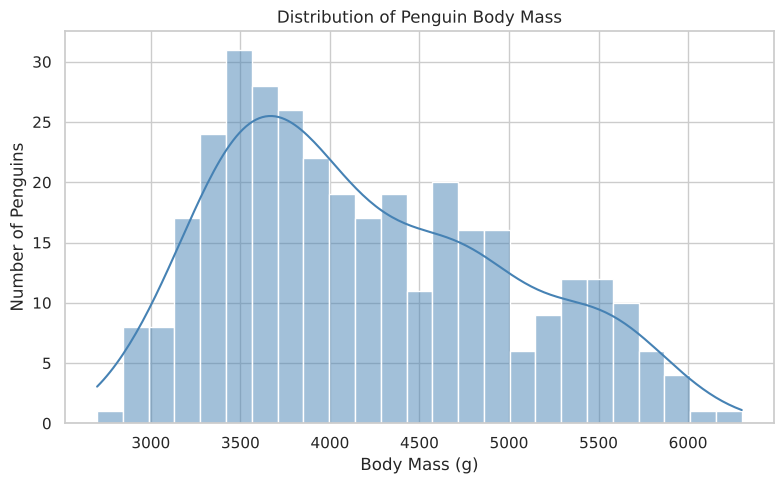

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["body_mass_g"], bins=25, kde=True, color="steelblue")
plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body Mass (g)")
plt.ylabel("Number of Penguins")
plt.tight_layout()
plt.savefig("figures/task6_histogram.png", dpi=150)
plt.show()

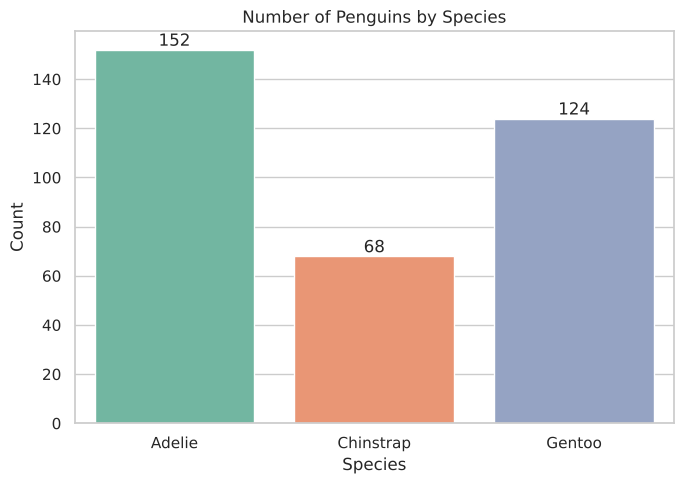

In [15]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df_clean, x="species", hue="species", palette="Set2", legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Number of Penguins by Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("figures/task6_barchart.png", dpi=150)
plt.show()

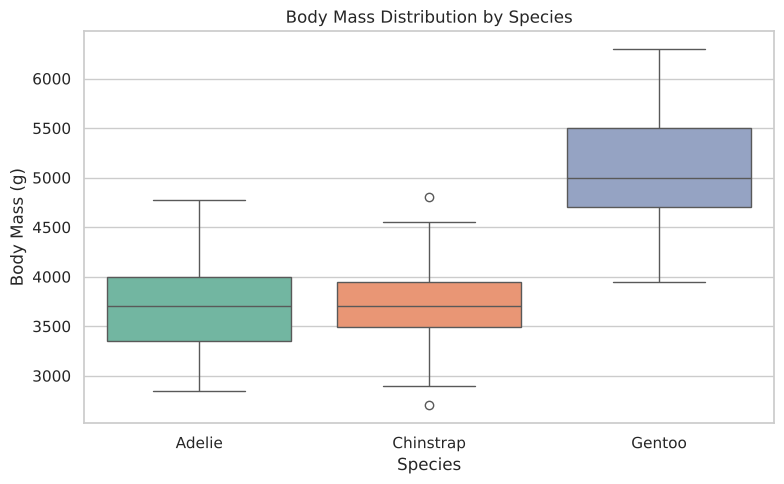

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="species", y="body_mass_g", hue="species", palette="Set2", legend=False)
plt.title("Body Mass Distribution by Species")
plt.xlabel("Species")
plt.ylabel("Body Mass (g)")
plt.tight_layout()
plt.savefig("figures/task6_boxplot.png", dpi=150)
plt.show()

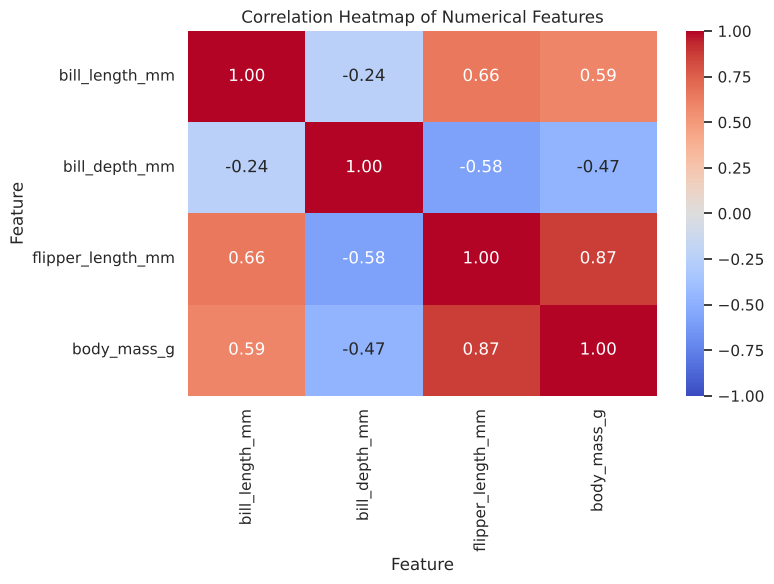

In [17]:
plt.figure(figsize=(8, 6))
corr = df_clean[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numerical Features")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/task6_heatmap.png", dpi=150)
plt.show()

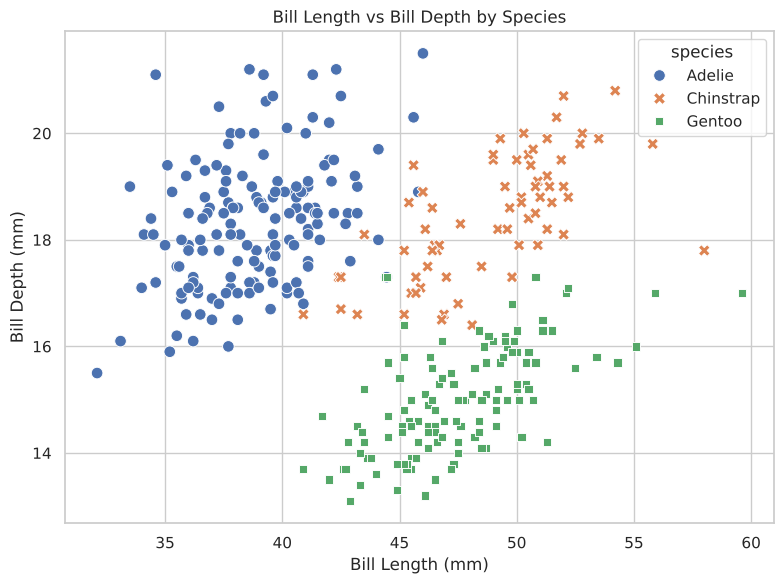

In [18]:
# Extra: scatter plot revealing Simpson's paradox for bill depth
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_clean, x="bill_length_mm", y="bill_depth_mm", hue="species", style="species", s=70)
plt.title("Bill Length vs Bill Depth by Species")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.tight_layout()
plt.savefig("figures/task6_scatter_extra.png", dpi=150)
plt.show()

## Task 7 

In [19]:
df_clean["bill_ratio"] = (df_clean["bill_length_mm"] / df_clean["bill_depth_mm"]).round(3)
df_clean["body_mass_kg"] = (df_clean["body_mass_g"] / 1000).round(3)
display(df_clean[["species", "bill_length_mm", "bill_depth_mm", "bill_ratio", "body_mass_g", "body_mass_kg"]].head())
print(df_clean.groupby("species")["bill_ratio"].describe().round(2))

,species,bill_length_mm,bill_depth_mm,bill_ratio,body_mass_g,body_mass_kg
0,Adelie,39.10,18.7,2.091,3750.0,3.75
1,Adelie,39.50,17.4,2.270,3800.0,3.80
2,Adelie,40.30,18.0,2.239,3250.0,3.25
3,Adelie,44.45,17.3,2.569,4050.0,4.05
4,Adelie,36.70,19.3,1.902,3450.0,3.45


           count  mean   std   min   25%   50%   75%   max
species                                                   
Adelie     152.0  2.12  0.16  1.64  2.01  2.14  2.24  2.57
Chinstrap   68.0  2.65  0.15  2.35  2.56  2.66  2.73  3.26
Gentoo     124.0  3.17  0.18  2.57  3.06  3.16  3.28  3.61


## Task 8 

In [20]:
print("Categorical columns:", df_clean.select_dtypes(include="object").columns.tolist())
print("\nBEFORE encoding:")
display(df_clean[["species", "island", "sex"]].head())

Categorical columns: ['species', 'island', 'sex']

BEFORE encoding:


/tmp/ipykernel_161/1948992640.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("Categorical columns:", df_clean.select_dtypes(include="object").columns.tolist())


,species,island,sex
0,Adelie,Torgersen,Male
1,Adelie,Torgersen,Female
2,Adelie,Torgersen,Female
3,Adelie,Torgersen,Male
4,Adelie,Torgersen,Female


In [21]:
from sklearn.preprocessing import LabelEncoder

df_enc = df_clean.copy()

# Label Encoding on 'sex' (only two categories, so one column of 0/1 is enough)
le = LabelEncoder()
df_enc["sex_encoded"] = le.fit_transform(df_enc["sex"])
print("Label encoding mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

# One-Hot Encoding on nominal variables 'species' and 'island'
df_enc = pd.get_dummies(df_enc, columns=["species", "island"], dtype=int)

print("\nAFTER encoding:")
display(df_enc.head())
print("Shape before:", df_clean.shape, "-> after:", df_enc.shape)

Label encoding mapping: {'Female': np.int64(0), 'Male': np.int64(1)}

AFTER encoding:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,bill_ratio,body_mass_kg,sex_encoded,species_Adelie,species_Chinstrap,species_Gentoo,island_Biscoe,island_Dream,island_Torgersen
0,39.10,18.7,181.0,3750.0,Male,2.091,3.75,1,1,0,0,0,0,1
1,39.50,17.4,186.0,3800.0,Female,2.270,3.80,0,1,0,0,0,0,1
2,40.30,18.0,195.0,3250.0,Female,2.239,3.25,0,1,0,0,0,0,1
3,44.45,17.3,197.0,4050.0,Male,2.569,4.05,1,1,0,0,0,0,1
4,36.70,19.3,193.0,3450.0,Female,1.902,3.45,0,1,0,0,0,0,1


Shape before: (344, 9) -> after: (344, 14)


## Task 9 

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scale_cols = ["bill_length_mm", "flipper_length_mm", "body_mass_g"]

# Split FIRST, then fit the scalers on the training data only (avoids data leakage)
train, test = train_test_split(df_enc, test_size=0.2, random_state=42, stratify=df_clean["species"])
print("Train:", train.shape, "| Test:", test.shape)

mm = MinMaxScaler().fit(train[scale_cols])
ss = StandardScaler().fit(train[scale_cols])

train_mm = pd.DataFrame(mm.transform(train[scale_cols]), columns=[c + "_minmax" for c in scale_cols], index=train.index)
train_ss = pd.DataFrame(ss.transform(train[scale_cols]), columns=[c + "_std" for c in scale_cols], index=train.index)

comparison = pd.concat([train[scale_cols], train_mm, train_ss], axis=1)
print("\nComparison table (first 8 training rows):")
display(comparison.head(8).round(3))

Train: (275, 14) | Test: (69, 14)

Comparison table (first 8 training rows):


,bill_length_mm,flipper_length_mm,body_mass_g,bill_length_mm_minmax,flipper_length_mm_minmax,body_mass_g_minmax,bill_length_mm_std,flipper_length_mm_std,body_mass_g_std
98,33.1,178.0,2900.0,0.000,0.102,0.056,-2.006,-1.643,-1.635
114,39.6,191.0,3900.0,0.245,0.322,0.333,-0.817,-0.707,-0.387
118,35.7,189.0,3350.0,0.098,0.288,0.181,-1.530,-0.851,-1.073
303,50.0,224.0,5350.0,0.638,0.881,0.736,1.084,1.669,1.422
343,49.9,213.0,5400.0,0.634,0.695,0.750,1.066,0.877,1.485
269,45.2,215.0,5300.0,0.457,0.729,0.722,0.206,1.021,1.360
141,40.6,187.0,3475.0,0.283,0.254,0.215,-0.634,-0.995,-0.917
259,48.7,208.0,5350.0,0.589,0.610,0.736,0.846,0.517,1.422


In [23]:
print("Summary statistics after scaling (training data):")
display(pd.concat([train[scale_cols].describe().loc[["mean", "std", "min", "max"]].add_suffix(" (original)"),
                   train_mm.describe().loc[["mean", "std", "min", "max"]],
                   train_ss.describe().loc[["mean", "std", "min", "max"]]], axis=1).round(3).T)

# Test data uses the scalers fitted on training data
test_mm = mm.transform(test[scale_cols])
test_ss = ss.transform(test[scale_cols])
print("Test min-max range (can slightly exceed 0-1):", test_mm.min().round(3), test_mm.max().round(3))

Summary statistics after scaling (training data):


,mean,std,min,max
bill_length_mm (original),44.071,5.480,33.100,59.600
flipper_length_mm (original),200.818,13.917,172.000,231.000
body_mass_g (original),4210.091,802.918,2700.000,6300.000
bill_length_mm_minmax,0.414,0.207,0.000,1.000
flipper_length_mm_minmax,0.488,0.236,0.000,1.000
body_mass_g_minmax,0.419,0.223,0.000,1.000
bill_length_mm_std,-0.000,1.002,-2.006,2.839
flipper_length_mm_std,0.000,1.002,-2.074,2.173
body_mass_g_std,0.000,1.002,-1.884,2.608


Test min-max range (can slightly exceed 0-1): -0.038 0.983


## Task 10 

In [24]:
final_df = df_enc.copy()

print("Missing values remaining:", int(final_df.isnull().sum().sum()))
print("Duplicate rows remaining:", int(final_df.duplicated().sum()))
print("Non-numeric columns left:", final_df.select_dtypes(exclude=np.number).columns.tolist())
display(final_df.head(10))
display(final_df.dtypes)

Missing values remaining: 0
Duplicate rows remaining: 0
Non-numeric columns left: ['sex']


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,bill_ratio,body_mass_kg,sex_encoded,species_Adelie,species_Chinstrap,species_Gentoo,island_Biscoe,island_Dream,island_Torgersen
0,39.10,18.7,181.0,3750.0,Male,2.091,3.750,1,1,0,0,0,0,1
1,39.50,17.4,186.0,3800.0,Female,2.270,3.800,0,1,0,0,0,0,1
2,40.30,18.0,195.0,3250.0,Female,2.239,3.250,0,1,0,0,0,0,1
3,44.45,17.3,197.0,4050.0,Male,2.569,4.050,1,1,0,0,0,0,1
4,36.70,19.3,193.0,3450.0,Female,1.902,3.450,0,1,0,0,0,0,1
5,39.30,20.6,190.0,3650.0,Male,1.908,3.650,1,1,0,0,0,0,1
6,38.90,17.8,181.0,3625.0,Female,2.185,3.625,0,1,0,0,0,0,1
7,39.20,19.6,195.0,4675.0,Male,2.000,4.675,1,1,0,0,0,0,1
8,34.10,18.1,193.0,3475.0,Male,1.884,3.475,1,1,0,0,0,0,1
9,42.00,20.2,190.0,4250.0,Male,2.079,4.250,1,1,0,0,0,0,1


bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
bill_ratio           float64
body_mass_kg         float64
sex_encoded            int64
species_Adelie         int64
species_Chinstrap      int64
species_Gentoo         int64
island_Biscoe          int64
island_Dream           int64
island_Torgersen       int64
dtype: object

In [25]:
final_df.to_csv("penguins_cleaned.csv", index=False)
check = pd.read_csv("penguins_cleaned.csv")
print(f"Saved penguins_cleaned.csv -> Final rows: {check.shape[0]}, Final columns: {check.shape[1]}")

Saved penguins_cleaned.csv -> Final rows: 344, Final columns: 14
